# Previsão de Evasão de Clientes (Churn) Utilizando Machine Learning

## Introdução

A retenção de clientes é um dos principais desafios enfrentados por empresas de telecomunicações. A perda de clientes, conhecida como churn, ocorre quando um consumidor decide cancelar os serviços contratados, o que pode gerar impactos financeiros significativos para a empresa.

Neste contexto, técnicas de Machine Learning podem ser utilizadas para identificar padrões de comportamento e prever quais clientes apresentam maior probabilidade de cancelar seus contratos. Essas previsões permitem que a empresa tome medidas preventivas, como ofertas especiais, melhoria no atendimento ou programas de fidelização.

O objetivo deste projeto é desenvolver um modelo de aprendizado de máquina capaz de prever a ocorrência de churn com base em informações dos clientes, como tempo de permanência na empresa, serviços contratados, tipo de contrato e gastos mensais.

Para isso, serão realizadas as etapas de carregamento e exploração dos dados, pré-processamento, tratamento de valores ausentes, transformação de variáveis categóricas, treinamento do modelo e avaliação dos resultados. Além disso, serão aplicadas boas práticas de Machine Learning, incluindo validação adequada, prevenção de overfitting, regularização e cuidados para evitar vazamento de informações.

Ao final, será possível analisar o desempenho do modelo e compreender quais características estão mais relacionadas ao cancelamento dos serviços pelos clientes.

## Objetivo do Projeto

Desenvolver e avaliar um modelo de classificação capaz de prever se um cliente irá cancelar ou continuar utilizando os serviços da empresa de telecomunicações, utilizando o dataset Telco Customer Churn.

### Importando as bibliotecas e conhecendo o dataframe

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head(1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

OBS: Identifiquei que a coluna "TotalCharges" foi carregada como string. Sendo necessário tranformá-la em float

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [7]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

OBS: Identificou-se na coluna "TotalCharges" valores ausentes que pode prejudicar o treinamento de modelos de Machine Learning, uma vez que o algoritmo não consegue realizar cálculos utilizando informações inexistentes.

In [8]:
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

OBS: Para solucionar esse problema, os valores ausentes foram substituídos pela mediana da coluna. A mediana foi escolhida porque representa um valor central dos dados e é menos influenciada por valores muito altos ou muito baixos, tornando o preenchimento mais robusto e confiável.

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Remoção de Variáveis Irrelevantes

A coluna customerID foi removida do conjunto de dados, pois representa apenas um identificador único para cada cliente. Como essa informação não possui relação com o cancelamento dos serviços, sua utilização não contribui para o treinamento do modelo e pode adicionar ruído ao processo de aprendizagem.

In [10]:
df.drop("customerID", axis=1, inplace=True)

C:\Users\luisg\AppData\Local\Temp\ipykernel_22028\3009645607.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop("customerID", axis=1, inplace=True)


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

### Conversão da variável Alvo

A variável Churn representa o cancelamento dos serviços pelos clientes e estava originalmente armazenada em formato textual (Yes e No). Para permitir a utilização pelos algoritmos de Machine Learning, os valores foram convertidos para formato numérico, onde 0 representa clientes que permaneceram na empresa e 1 representa clientes que cancelaram o serviço.

In [12]:
df["Churn"] = df["Churn"].map(
    {
        "No": 0,
        "Yes": 1
    }
)

In [13]:
df["Churn"].head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

### Convertendo texto em números

O dataset possui diversas variáveis categóricas representadas por texto, como gênero, tipo de contrato e serviço de internet. Como os algoritmos de Machine Learning operam com dados numéricos, foi utilizada a técnica de One-Hot Encoding por meio da função get_dummies(). Essa técnica cria variáveis binárias (0 ou 1 / False ou True) para representar cada categoria existente nos dados.

In [14]:
df = pd.get_dummies(
    df,
    drop_first=True
)

In [15]:
df.head(10)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
5,0,8,99.65,820.50,1,False,False,False,True,False,...,False,True,False,True,False,False,True,False,True,False
6,0,22,89.10,1949.40,0,True,False,True,True,False,...,False,True,False,False,False,False,True,True,False,False
7,0,10,29.75,301.90,0,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,True
8,0,28,104.80,3046.05,1,False,True,False,True,False,...,False,True,False,True,False,False,True,False,True,False
9,0,62,56.15,3487.95,0,True,False,True,True,False,...,False,False,False,False,True,False,False,False,False,False


In [16]:
df.columns.tolist()

['SeniorCitizen',
 'tenure',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'gender_Male',
 'Partner_Yes',
 'Dependents_Yes',
 'PhoneService_Yes',
 'MultipleLines_No phone service',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_No internet service',
 'OnlineSecurity_Yes',
 'OnlineBackup_No internet service',
 'OnlineBackup_Yes',
 'DeviceProtection_No internet service',
 'DeviceProtection_Yes',
 'TechSupport_No internet service',
 'TechSupport_Yes',
 'StreamingTV_No internet service',
 'StreamingTV_Yes',
 'StreamingMovies_No internet service',
 'StreamingMovies_Yes',
 'Contract_One year',
 'Contract_Two year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

### Separando as variáveis de entrada da variável alvo

In [17]:
X = df.drop("Churn", axis=1)

y = df["Churn"]


Em problemas de aprendizado supervisionado, os dados são divididos em variáveis de entrada (X) e variável alvo (y).
As variáveis de entrada correspondem às características utilizadas pelo modelo para realizar previsões, como tempo de permanência do cliente, valor mensal da assinatura e serviços contratados.
Já a variável alvo representa aquilo que se deseja prever. Neste projeto, a variável alvo é Churn, que indica se o cliente permaneceu na empresa (0) ou cancelou os serviços (1).

### Separação dos dados em treino e teste

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Após o pré-processamento, o conjunto de dados foi dividido em subconjuntos de treinamento e teste utilizando a função train_test_split(). Foram destinados 80% dos registros para treinamento do modelo e 20% para avaliação.
A separação entre treinamento e teste é uma etapa fundamental em Machine Learning, pois permite avaliar a capacidade de generalização do modelo em dados não utilizados durante o treinamento. Dessa forma, é possível obter uma estimativa mais realista do desempenho do algoritmo em situações reais.
Além disso, foi utilizado o parâmetro stratify=y para preservar a proporção original das classes da variável alvo em ambos os subconjuntos, garantindo uma distribuição equilibrada entre os dados de treinamento e teste.

### Normalização dos Dados

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

OBS: As variáveis presentes no dataset possuem escalas diferentes. Enquanto algumas apresentam valores baixos, como o tempo de permanência do cliente (tenure), outras podem atingir valores muito maiores, como o gasto total (TotalCharges).
Para evitar que variáveis com valores mais elevados exerçam influência excessiva durante o treinamento do modelo, foi realizada a normalização utilizando o algoritmo StandardScaler.


O ajuste da escala foi realizado apenas nos dados de treinamento por meio do método fit_transform(). Em seguida, a mesma transformação foi aplicada aos dados de teste utilizando apenas o método transform(), evitando vazamento de informações entre os conjuntos de dados.

### Treinamento do modelo

Será utilizado a Regressão logística. Apesar do nome "regressão", esse modelo é um algoritmo de classificação. ele responderá: "O cliente vai cancelar?"

In [20]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000)

modelo.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

OBS: Durante o treinamento da Regressão Logística, foi identificado um aviso de convergência relacionado ao limite de iterações do algoritmo. Para solucionar o problema, o parâmetro max_iter foi aumentado para 5000, permitindo que o modelo concluísse o processo de treinamento adequadamente.

In [21]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=5000)

modelo.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### Realização das previsões 

In [23]:
y_pred = modelo.predict(X_test)

### Verificando as 10 primeiras previsões

In [24]:
print("Previsões:")
print(y_pred[:10])

print("\nValores reais:")
print(y_test[:10].values)

Previsões:
[0 1 0 0 0 1 0 0 0 0]

Valores reais:
[0 0 0 0 0 0 0 0 0 1]


OBS: Após o treinamento da Regressão Logística, o modelo foi utilizado para realizar previsões sobre o conjunto de teste por meio do método predict(). Essa etapa tem como objetivo verificar como o algoritmo se comporta diante de dados que não foram utilizados durante o treinamento.

### Avaliação do modelo

In [25]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Acurácia: {accuracy:.4f}")

Acurácia: 0.8070


OBS: O que a acurácia mede: Quantas previsões o modelo acertou em relação ao total de previsões realizadas. Logo, em aproximadamente 80%, o modelo conseguiu prever corretamente se o cliente permaneceria ou cancelaria o serviço.

Analisando com "Classification Report"

A acurácia sozinha não conta toda a história.



In [26]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



OBS: Além da acurácia, utilizei o classification_report para obter uma análise mais detalhada do desempenho do modelo. 
Os resultados mostraram que a Regressão Logística teve um ótimo desempenho na identificação dos clientes que permaneceram na empresa, apresentando valores elevados de precisão, recall e F1-score para a classe 0.
Já para os clientes que realmente cancelaram os serviços (classe 1), o desempenho foi um pouco menor. Isso indica que o modelo ainda tem dificuldade em identificar todos os casos de cancelamento, embora consiga encontrar uma parte significativa deles.
De forma geral, considero que o modelo apresentou um resultado satisfatório, alcançando uma acurácia de aproximadamente 80,6%, o que significa que ele acertou cerca de 8 em cada 10 previsões realizadas. Esses resultados mostram que o algoritmo conseguiu aprender padrões importantes presentes nos dados e utilizá-los para prever o comportamento dos clientes.

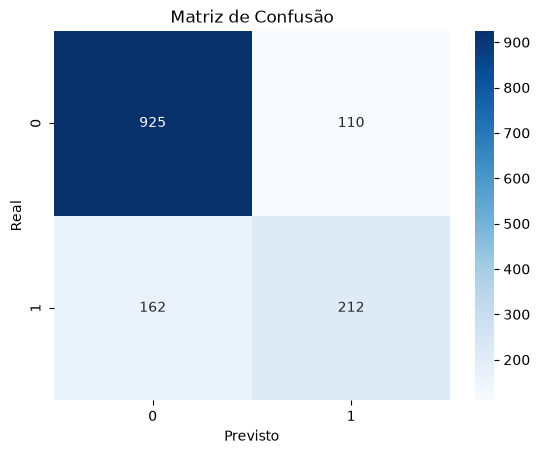

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão")

plt.show()

 ### Explicação da matriz
 925 clientes permaneceram e o modelo acertou.

 212 clientes cancelaram e o modelo acertou.

 110 clientes permaneceram, mas o modelo achou que cancelariam.

 162 clientes cancelaram, mas o modelo achou que permaneceriam.

### Verificando Overfitting

In [28]:
train_score = modelo.score(X_train, y_train)

test_score = modelo.score(X_test, y_test)

print(f"Acurácia no treino: {train_score:.4f}")
print(f"Acurácia no teste: {test_score:.4f}")

Acurácia no treino: 0.8060
Acurácia no teste: 0.8070


obs: Quando os resultados são muito semelhantes, isso indica que o modelo conseguiu generalizar bem o conhecimento aprendido, indicando não haver Overfitting

### Validação Cruzada

In [29]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(modelo,X_train,y_train,cv=5)

print(scores)

[0.82786158 0.80035492 0.80745342 0.79414374 0.79129663]


In [39]:
print(f"Média da validação cruzada: {scores.mean():.4f}")

Média da validação cruzada: 0.8048


OBS: Nessa abordagem, os dados são divididos em diferentes grupos e o treinamento é realizado várias vezes, utilizando combinações diferentes dos dados. Ao final, é calculada a média dos resultados obtidos.

A média da validação cruzada foi de 80,48%, valor muito próximo da acurácia obtida anteriormente no conjunto de teste (80,62%).

Essa proximidade indica que o modelo apresenta um comportamento estável e consistente, aumentando a confiança de que ele será capaz de realizar boas previsões também em novos conjuntos de dados.

## Conclusão

este projeto foi desenvolvido um modelo de Machine Learning para prever a evasão de clientes (churn) em uma empresa de telecomunicações utilizando o dataset Telco Customer Churn.

Inicialmente foram realizadas etapas de exploração e pré-processamento dos dados, incluindo tratamento de valores ausentes, remoção de atributos irrelevantes, transformação de variáveis categóricas e normalização dos dados. Em seguida, os dados foram divididos entre conjuntos de treinamento e teste para garantir uma avaliação adequada do modelo.

Foi utilizado o algoritmo de Regressão Logística para realizar a classificação dos clientes. O modelo alcançou uma acurácia de 80,62%, demonstrando boa capacidade de identificar padrões relacionados ao cancelamento dos serviços.

A análise da matriz de confusão e do relatório de classificação mostrou que o modelo foi especialmente eficiente na identificação dos clientes que permaneceram na empresa, embora ainda apresente algumas dificuldades para detectar todos os casos de cancelamento.

Por fim, a comparação entre os resultados de treino e teste não indicou sinais de overfitting, e a validação cruzada confirmou a consistência dos resultados obtidos. Dessa forma, concluo que o modelo desenvolvido apresentou um desempenho satisfatório para o problema proposto e demonstrou a aplicação prática dos principais conceitos estudados na disciplina de Machine Learning.